#Imports

In [1]:
!pip install qiskit
!pip install qiskit_aer
!pip install qiskit_ibm_runtime
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 56.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 MB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.0/109.0 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.9/363.9 kB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 13.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha25

In [15]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
from qiskit.transpiler import generate_preset_pass_manager

from math import pi

#E-bit Pairs

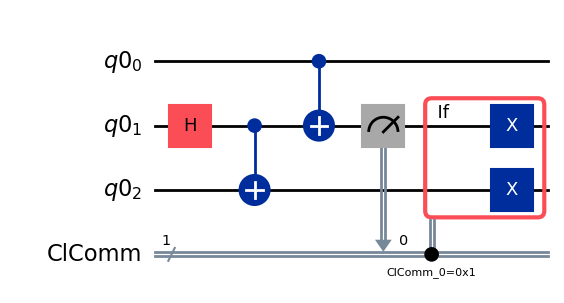

In [5]:
#q1 -> ctrl; q2 -> com1; q3 -> com2;
def cat_entangler() -> QuantumCircuit:
  qReg = QuantumRegister(3)
  cl_reg = ClassicalRegister(1, name='ClComm')
  cat_qc = QuantumCircuit(qReg,cl_reg)
  cat_qc.h(1)
  cat_qc.cx(1,2)

  cat_qc.cx(0,1)
  cat_qc.measure(1,0)
  with cat_qc.if_test((0,1)):
    cat_qc.x(1)
    cat_qc.x(2)

  return cat_qc

thingy = cat_entangler()
thingy.draw('mpl')

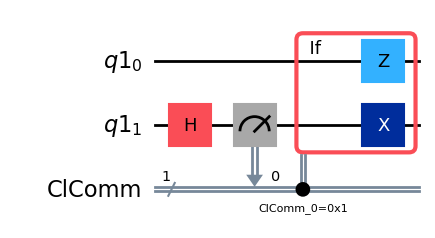

In [6]:
#q1 -> ctrl; q2 -> com2;
def cat_disentangler() -> QuantumCircuit:
  qReg = QuantumRegister(2)
  cl_reg = ClassicalRegister(1, name='ClComm')
  uncat_qc = QuantumCircuit(qReg,cl_reg)
  uncat_qc.h(1)
  uncat_qc.measure(1,0)
  with uncat_qc.if_test((0,1)):
    uncat_qc.z(0)
    uncat_qc.x(1)

  return uncat_qc

the_thingy = cat_disentangler()
the_thingy.draw('mpl')

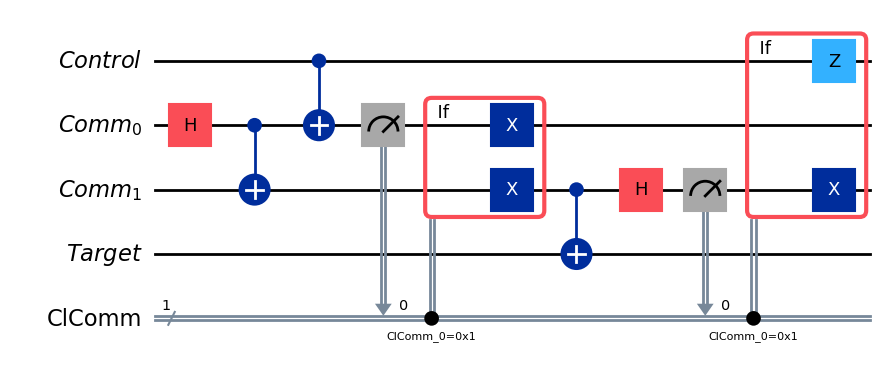

In [7]:
#Example usage of e-bit pairs
# Create Quantum Registers
control = QuantumRegister(1, name='Control')
comm = QuantumRegister(2, name='Comm')
target = QuantumRegister(1, name='Target')

# Create Classical Register
creg = ClassicalRegister(1, name='ClComm')

# Create Quantum Circuit
qc = QuantumCircuit(control, comm, target, creg)
qc_cat = cat_entangler()


qc = qc.compose(qc_cat, range(3), clbits=[creg[0]])
qc.cx(2,3)
qc = qc.compose(cat_disentangler(), [control[0],comm[1]], clbits=creg[0])


qc.draw('mpl')

#Distributed QFT (Vernec, 2025)

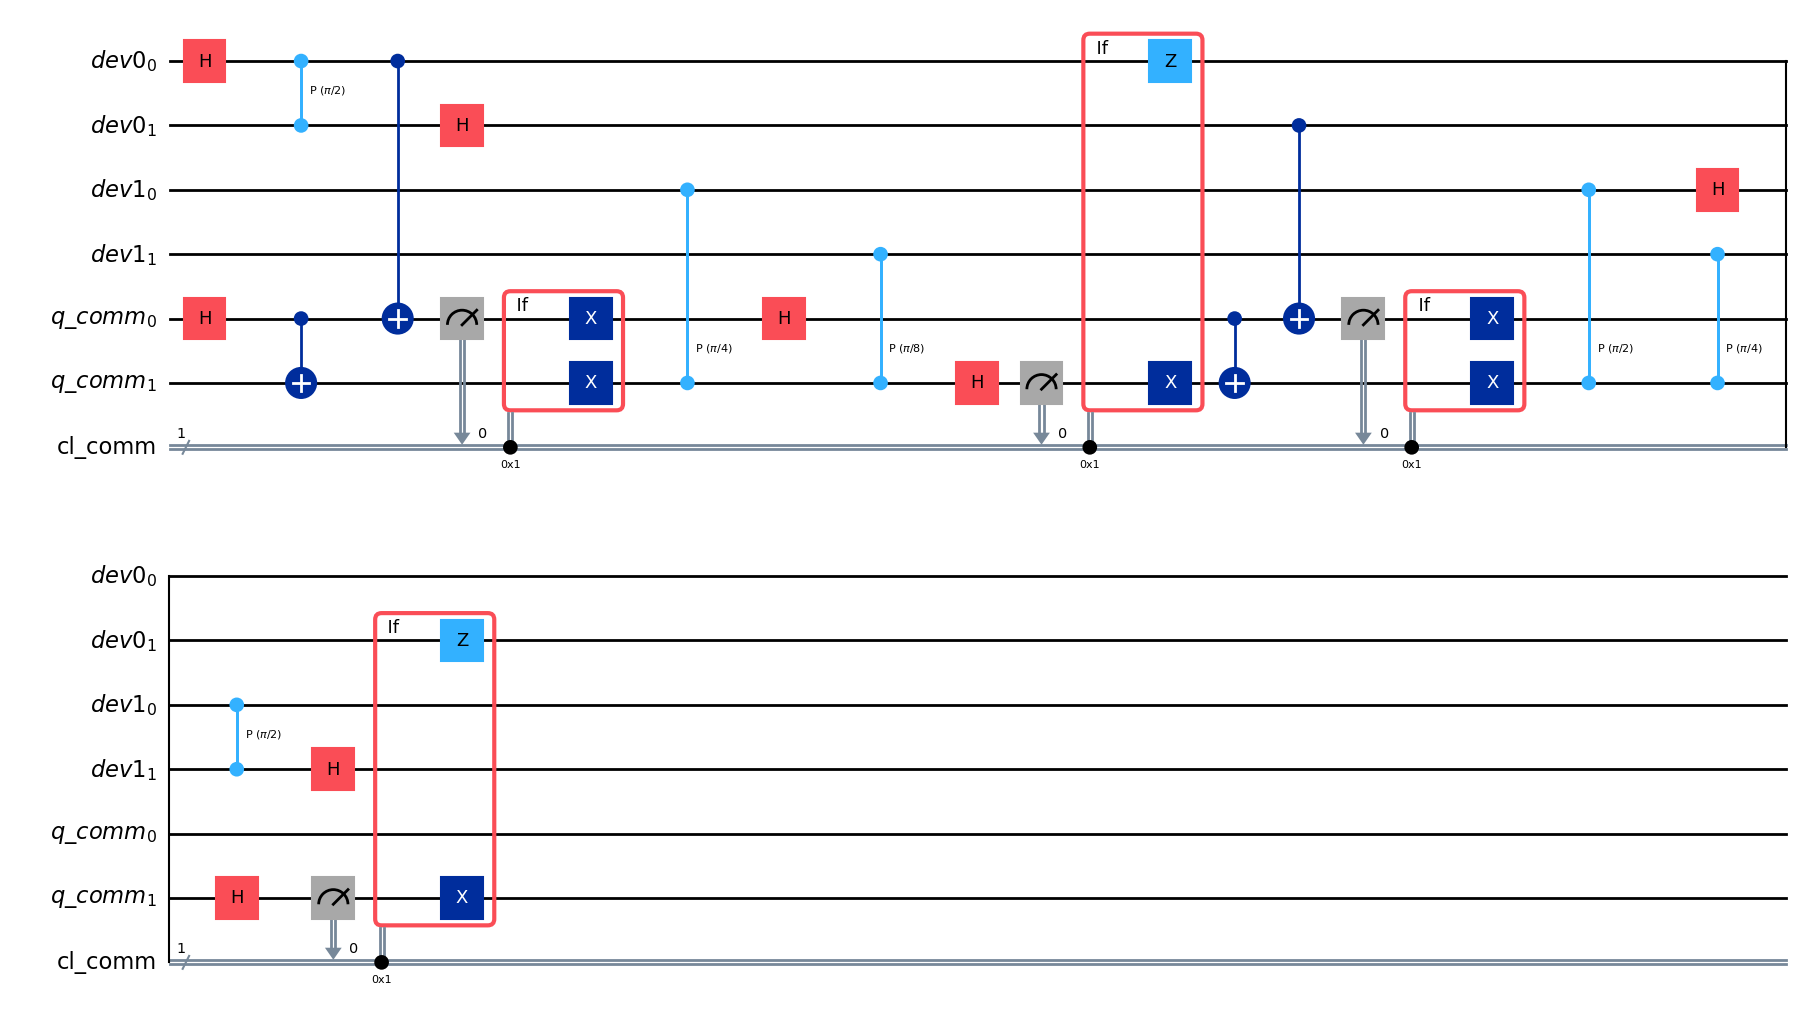

In [12]:
#assumes one communicative qubit per device, uniform device size
def qft_circuit_dist(n_qubits: int, n_devices : int, device_size : int) -> QuantumCircuit:
  if n_qubits > n_devices*device_size:
    print('not enough device space')
    return

  c = ClassicalRegister(1, 'cl_comm')
  qc = QuantumCircuit(c)


  #qubit allocation
  full_devices = min(n_qubits // device_size, n_devices)
  remainder = n_qubits % device_size

  for i in range(full_devices):
    qc.add_register(QuantumRegister(device_size, f'dev{i}'))

  if full_devices < n_devices and remainder > 0:
    qc.add_register(QuantumRegister(remainder, f'dev{full_devices}'))

  qc.add_register(QuantumRegister(n_devices, 'q_comm'))



  #circuit logic

  #loops through devices
  for dev_idx, qreg in enumerate(qc.qregs[:-1]):

    # print(f"QuantumRegister: {qreg.name}")

    for i, idx_qubit in enumerate(qreg):
      angleCoeff = 1
      # print(f"  Current qubit: {idx_qubit}")
      qc.h(idx_qubit)
      for next_qubit in qreg[i+1:]:
        # print(f"    Later qubit in same device: {next_qubit}")
        qc.cp(pi/(2**angleCoeff), idx_qubit, next_qubit)
        angleCoeff += 1


      #looping subsequent devices
      for later_dev_idx, later_dev in enumerate(qc.qregs[dev_idx + 1:-1], dev_idx+1):
        #cat entangler
        qc.h(qc.qregs[-1][dev_idx])
        qc.cx(qc.qregs[-1][dev_idx], qc.qregs[-1][later_dev_idx])

        qc.cx(idx_qubit, qc.qregs[-1][dev_idx])
        qc.measure(qc.qregs[-1][dev_idx], c)
        with qc.if_test((c,1)):
          qc.x(qc.qregs[-1][dev_idx])
          qc.x(qc.qregs[-1][later_dev_idx])


        for other_qubit in later_dev:
          # print(f"    Qubit from subsequent device {later_dev.name}: {other_qubit}")
          qc.cp(pi/(2**angleCoeff), qc.qregs[-1][later_dev_idx], other_qubit)
          angleCoeff += 1


        #cat disentangler
        qc.h(qc.qregs[-1][later_dev_idx])
        qc.measure(qc.qregs[-1][later_dev_idx], c)
        with qc.if_test((c,1)):
          qc.z(idx_qubit)
          qc.x(qc.qregs[-1][later_dev_idx])



  return qc



dist_qft = qft_circuit_dist(4,2,2)
dist_qft.draw('mpl')

##Transpilation

In [17]:
backend = FakeMarrakesh()
pm = generate_preset_pass_manager(optimization_level = 3, backend = backend)

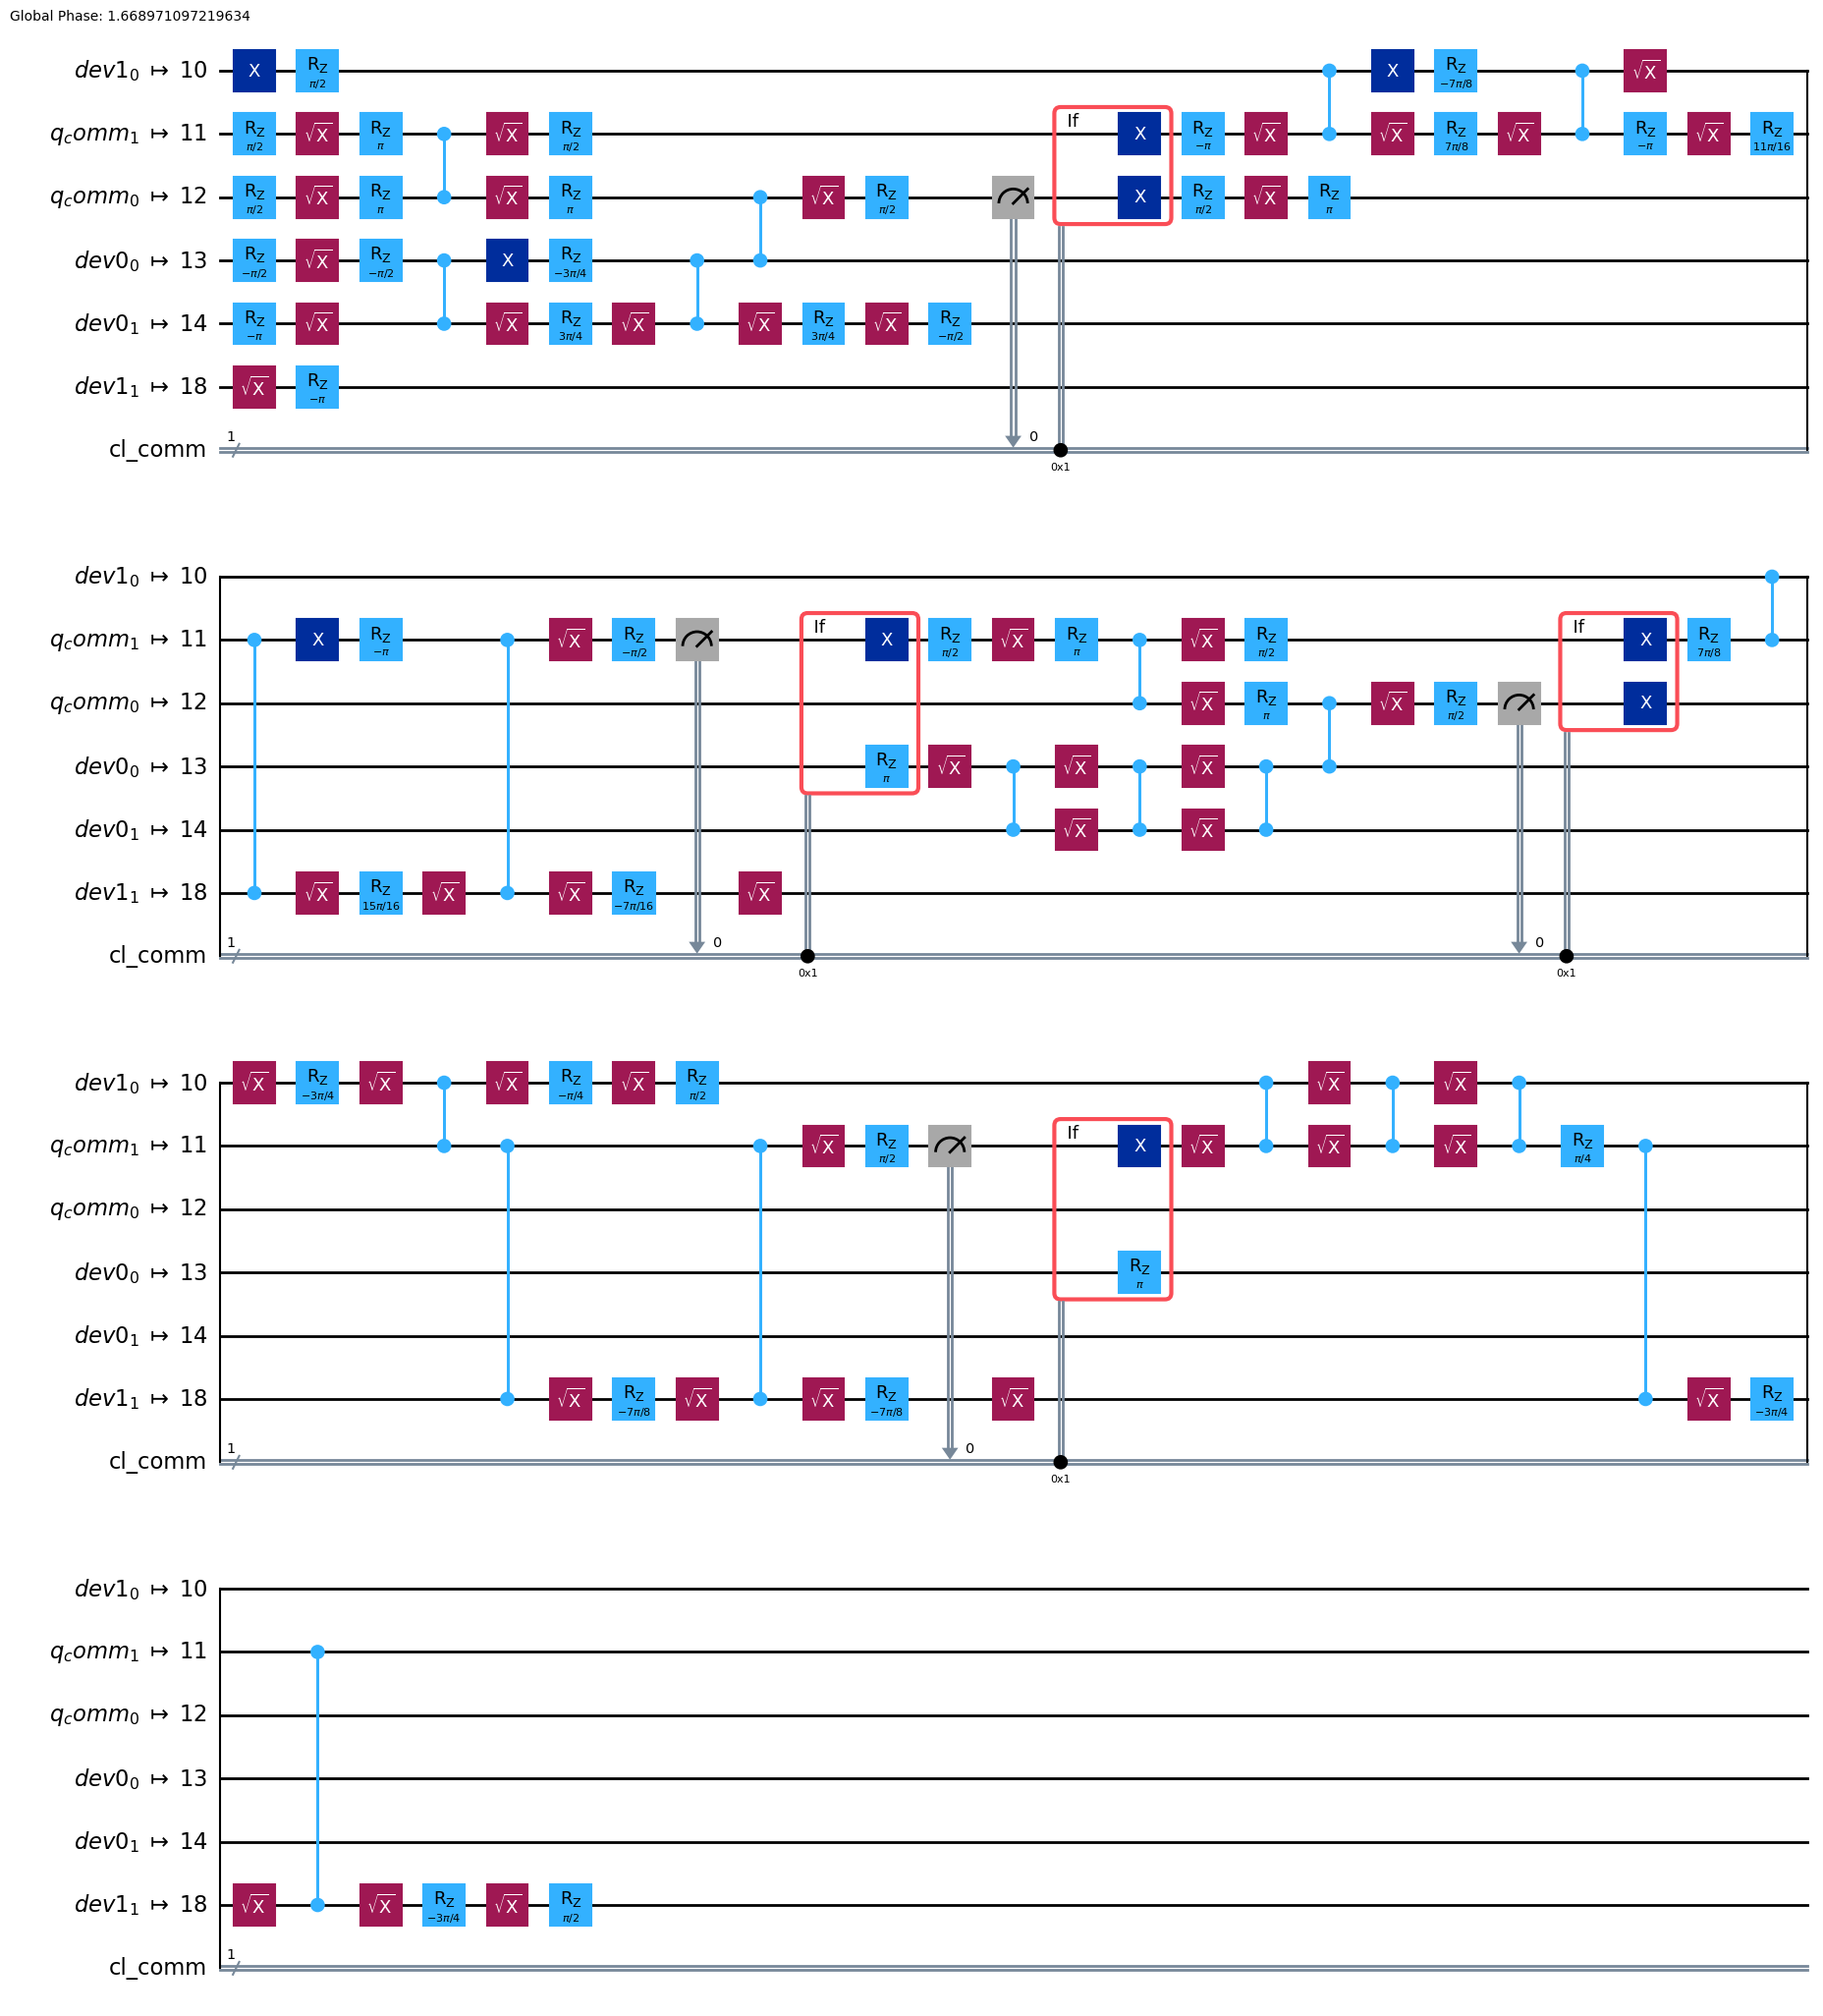

In [18]:
tdist_qft = pm.run(dist_qft)
tdist_qft.draw('mpl')